In [1]:
# Employee Salary Prediction

In [2]:
# Step 1: Import libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [4]:
# Step 2: Load dataset

In [5]:
df = pd.read_csv("hr_regression_dataset.csv")

df.head()

,experience,performance,role_level,salary
0,0,2.266659,1,19138.228905
1,20,1.474785,1,52520.174836
2,19,2.878807,4,94270.140793
3,2,1.566725,3,38506.902016
4,19,3.530433,3,85959.434566


In [6]:
# Step 3: Explore the dataset

In [7]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Shape: (10000, 4)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   experience   10000 non-null  int64  
 1   performance  10000 non-null  float64
 2   role_level   10000 non-null  int64  
 3   salary       10000 non-null  float64
dtypes: float64(2), int64(2)
memory usage: 312.6 KB

Statistical Summary:
         experience   performance    role_level         salary
count  10000.000000  10000.000000  10000.000000   10000.000000
mean      14.570600      2.991163      2.997000   74059.666455
std        8.637828      1.147201      1.414352   23051.632392
min        0.000000      1.000109      1.000000   10458.089216
25%        7.000000      2.009630      2.000000   57715.991313
50%       15.000000      2.989070      3.000000   73891.480704
75%       22.000000      3.975798      4.000000   90707.098391
max       29.00

In [8]:
# Step 4: Exploratory Data Analysis (EDA)

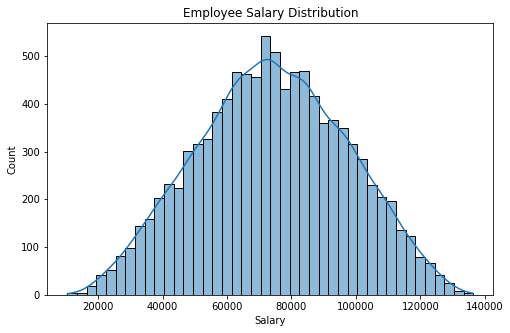

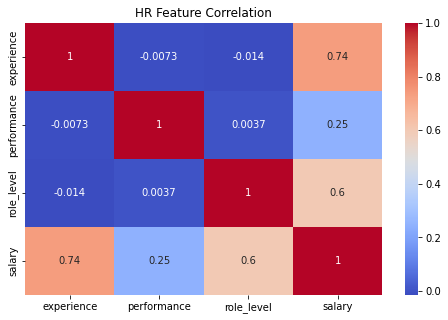

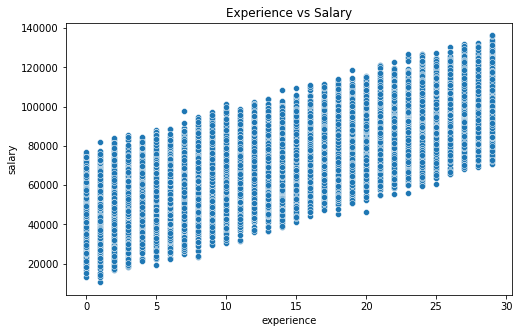

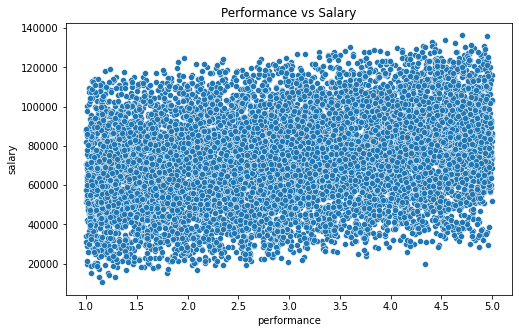

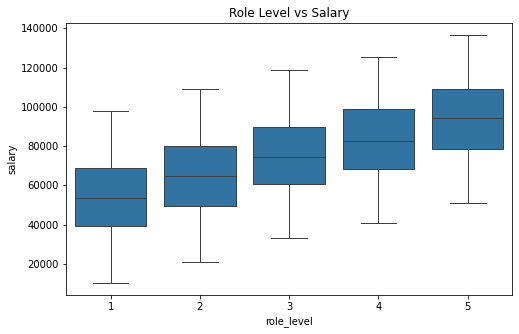

In [9]:
# Salary distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["salary"], kde=True)
plt.title("Employee Salary Distribution")
plt.xlabel("Salary")
plt.show()

# Correlation heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("HR Feature Correlation")
plt.show()

# Experience vs Salary
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="experience", y="salary")
plt.title("Experience vs Salary")
plt.show()

# Performance vs Salary
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="performance", y="salary")
plt.title("Performance vs Salary")
plt.show()

# Role Level vs Salary
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="role_level", y="salary")
plt.title("Role Level vs Salary")
plt.show()

In [10]:
# Step 5: Define independent and dependent variables

In [11]:
X = df[["experience", "performance", "role_level"]]

y = df["salary"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   experience  performance  role_level
0           0     2.266659           1
1          20     1.474785           1
2          19     2.878807           4
3           2     1.566725           3
4          19     3.530433           3

Target:
0    19138.228905
1    52520.174836
2    94270.140793
3    38506.902016
4    85959.434566
Name: salary, dtype: float64


In [12]:
# Step 6: Split the dataset

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (8000, 3)
Testing Data: (2000, 3)


In [14]:
# Step 7: Build and train the Linear Regression model

In [15]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

model.fit(X_train, y_train)

print("Model Training Completed!")

Model Training Completed!


In [16]:
# Step 8: Make predictions

In [17]:
y_pred = model.predict(X_test)

print("Actual Salary:")
print(y_test.head(10).values)

print("\nPredicted Salary:")
print(y_pred[:10])

Actual Salary:
[ 79791.9636883  117477.536042    73895.2014474   59380.14974219
  76695.34382057  79938.88727634  23391.0991577   74825.24396805
  91242.49237947  79652.28672437]

Predicted Salary:
[ 78597.91214438 117853.0916769   76715.28248326  58028.89843123
  72760.44064414  79191.29975342  25827.91650098  75086.89857019
  92267.75398748  74685.50016912]


In [18]:
# Step 9: Evaluate the model

In [19]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("-------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Model Evaluation Results
-------------------------
MAE: 2401.4182486802115
MSE: 8877884.279976273
RMSE: 2979.5778694265186
R2 Score: 0.9831744816360953


In [20]:
# Step 10: Visualize actual vs predicted salary

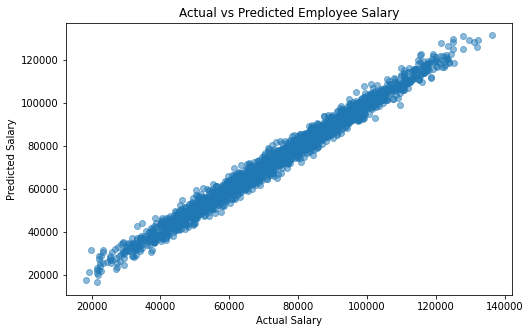

In [21]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")

plt.title("Actual vs Predicted Employee Salary")

plt.show()

In [22]:
# Step 11: Predict salary for a new employee

In [23]:
new_employee = pd.DataFrame({
    "experience": [5],
    "performance": [4.0],
    "role_level": [2]
})

predicted_salary = model.predict(new_employee)

print("Predicted Employee Salary:", round(predicted_salary[0], 2))

Predicted Employee Salary: 50057.94
